In [2]:

import matplotlib.pyplot as plt
import librosa
import numpy as np
import pandas as pd
from scipy.fft import fft, fftfreq
from scipy.signal import find_peaks

Frecuencia de muestreo: 44100
Tamaño de la señal: (152064,)


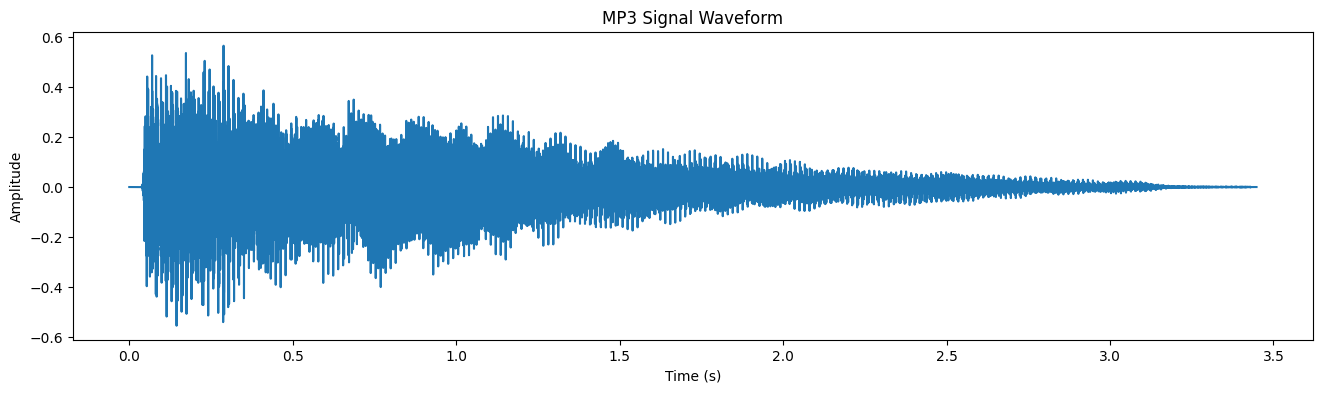

In [ ]:
signal, fs= librosa.load("Nota_CM_piano.mp3", sr=None)
print("Frecuencia de muestreo:", fs)
print("Tamaño de la señal:", signal.shape)

t = librosa.samples_to_time(np.arange(len(signal)), sr=sr)

plt.figure(figsize=(16, 4))
plt.plot(times,signal)
plt.title("MP3 Signal Waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()

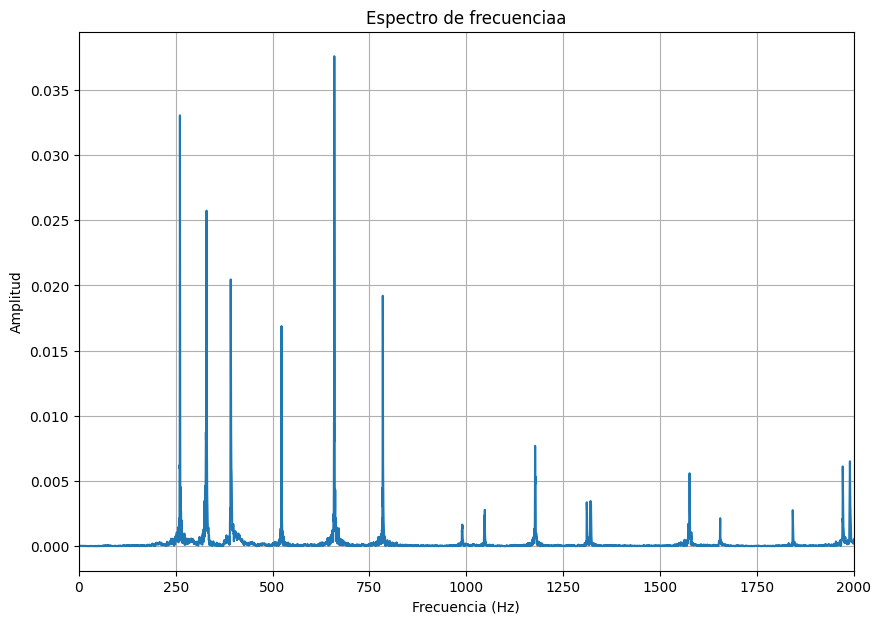

In [ ]:
#FFT usando SciPy
Y_sp = fft(signal) #FFT con SciPy
freq_sp = fftfreq(N, d=1/fs)

#otra vez tomamos solo las vfrecuencias positivas
freq_positive_sp = freq_sp[:N//2]
amp_positive_sp = 2/N*np.abs(Y_sp[:N//2])

plt.figure(figsize=(10, 7))
plt.plot(freq_positive_sp, amp_positive_sp)
plt.title("Espectro de frecuenciaa")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.xlim(0, 2000)
plt.grid()
plt.show()

#Used the rutine created in class FT(x,y). Modify it and do the FT to the signal. Do you get the same results?

In [ ]:
"""
Calculamos una transformada de Fourier aproximada usando suma discreta.

t: arreglo de tiempos
y: señal de audio
f_values: frecuencias donde se evalúa la transformada
"""

def FT_audio(t, y, f_values):
    dt= t[1]- t[0]
    resultados = []

    for f in f_values:
        F= np.sum(y*np.exp(-1j*2*np.pi*f*t))*dt
        amp=np.abs(F)
        real=F.real
        imag=F.imag
        ang=np.arctan2(imag, real)

        resultados.append([f,real,imag,amp,ang])

    df= pd.DataFrame(resultados,columns=["f","ReF","ImF","AMP","ANG"])

    return df

# Tomamos un fragmento de la señal para que la FT manual sea más rápida
duracion= 2  # segundos
M =int(duracion*fs)

signal_short=signal[:M]
t_short=t[:M]

f_values= np.linspace(0, 2000, 1000)
df_ft = FT_audio(t_short, signal_short, f_values)
df_ft.head()

,f,ReF,ImF,AMP,ANG
0,0.000000,-0.000099,0.000000,0.000099,3.141593
1,2.002002,0.000007,0.000033,0.000033,1.351225
2,4.004004,-0.000011,0.000035,0.000036,1.868954
3,6.006006,0.000029,0.000023,0.000037,0.679336
4,8.008008,0.000057,0.000004,0.000057,0.070386


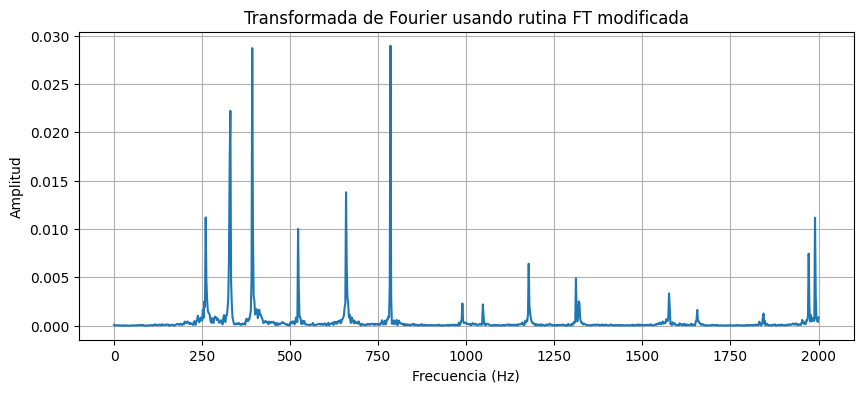

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(df_ft["f"], df_ft["AMP"])
plt.title("Transformada de Fourier usando rutina FT modificada")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.grid()
plt.show()

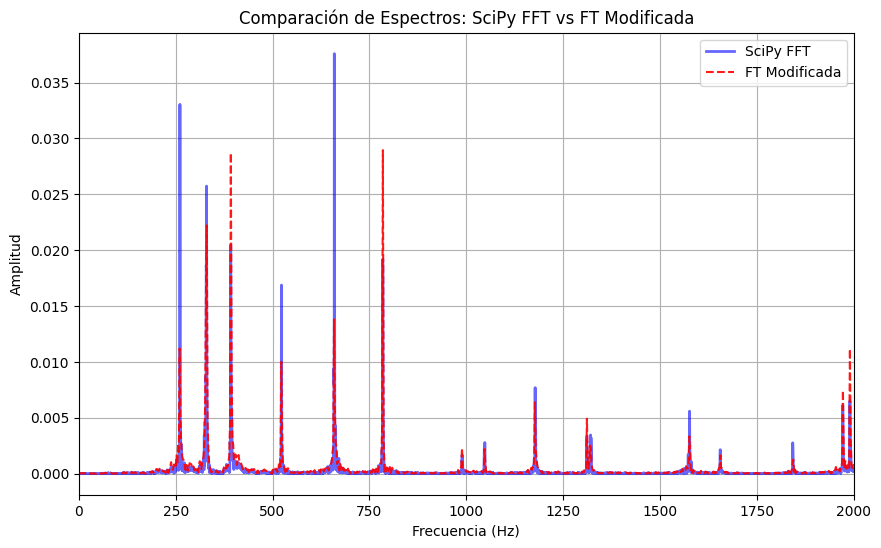

In [ ]:
plt.figure(figsize=(10, 6))

# Gráfica de la FFT de SciPy
plt.plot(freq_positive_sp, amp_positive_sp, label='SciPy FFT', color='blue', alpha=0.6, linewidth=2)

# Gráfica de la FT modificada (DataFrame df_ft)
plt.plot(df_ft["f"], df_ft["AMP"], label='FT Modificada', color='red', alpha=0.9, linewidth=1.5, linestyle='--')

plt.title("Comparación de Espectros: SciPy FFT vs FT Modificada")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.xlim(0, 2000) # Mantengo el límite que tenías en tu código
plt.grid(True)
plt.legend()
plt.show()

# Do the FFT for an Imagen

Una vez creada una rutina *custom* de FT(X,Y) llegamos a unos resultados muy parecidos.

In [4]:
def trdj2D(matriz):
    alto, ancho = matriz.shape
    matriz_filas = np.zeros((alto, ancho), dtype=complex)

    #Aplicar TRDJ a cada fila
    for i in range(alto):
        matriz_filas[i, :] = TRDJ(matriz[i, :])

    resultado_2d = np.zeros((alto, ancho), dtype=complex)

    # Aplicar TRDJ a cada columna del resultado anterior
    for j in range(ancho):
        resultado_2d[:, j] = TRDJ(matriz_filas[:, j])

    return resultado_2d

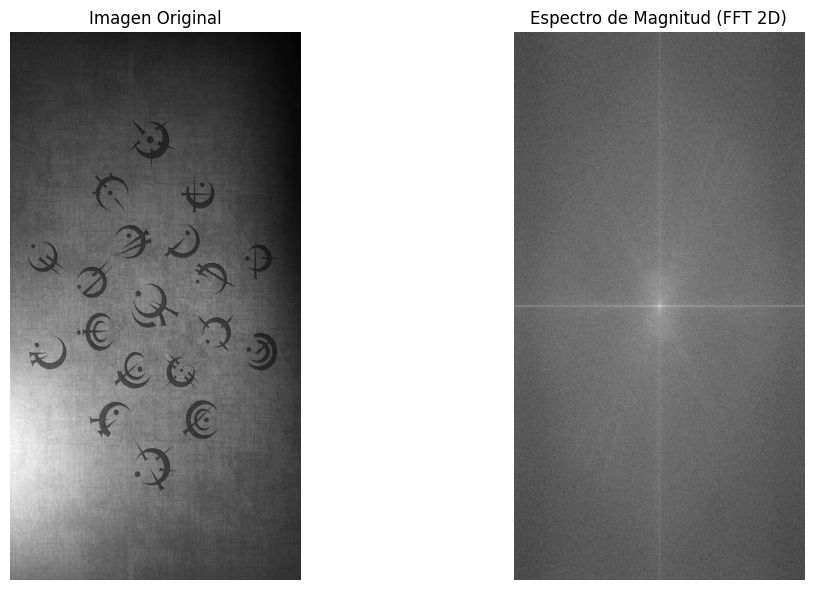

In [10]:

import cv2
imagen = cv2.imread('FFT.jpg', cv2.IMREAD_GRAYSCALE)

if imagen is None:
    raise ValueError("No se pudo cargar la imagen. Verifica la ruta.")

f_transform = np.fft.fft2(imagen)
f_shift = np.fft.fftshift(f_transform)
magnitud = 20 * np.log(np.abs(f_shift) + 1)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(magnitud, cmap='gray')
plt.title('Espectro de Magnitud (FFT 2D)')
plt.axis('off')

plt.tight_layout()
plt.show()

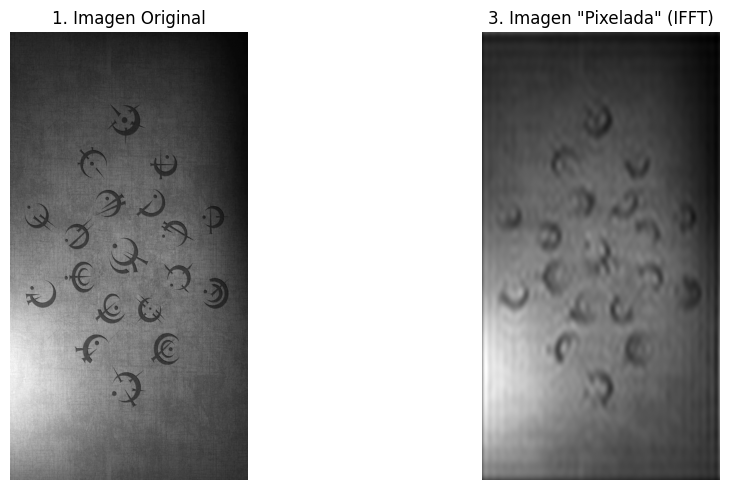

In [15]:

imagen = cv2.imread('FFT.jpg', cv2.IMREAD_GRAYSCALE)

f_transform = np.fft.fft2(imagen)
f_shift = np.fft.fftshift(f_transform)

filas, columnas = imagen.shape
centro_fila, centro_columna = filas // 2, columnas // 2

radio = 30
mascara = np.zeros((filas, columnas), np.uint8)
mascara[centro_fila - radio : centro_fila + radio,
        centro_columna - radio : centro_columna + radio] = 1

f_shift_filtrado = f_shift * mascara

magnitud_filtrada = 20 * np.log(np.abs(f_shift_filtrado) + 1)

# --- TRANSFORMADA INVERSA ---
# Deshacemos el centrado del espectro filtrado
f_ishift = np.fft.ifftshift(f_shift_filtrado)

# Aplicamos la inversa
img_reconstruida_compleja = np.fft.ifft2(f_ishift)
imagen_pixelada = np.abs(img_reconstruida_compleja)

# --- VISUALIZACIÓN ---
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap='gray')
plt.title('1. Imagen Original')
plt.axis('off')


plt.subplot(1, 3, 2)
plt.imshow(imagen_pixelada, cmap='gray')
plt.title('3. Imagen "Pixelada" (IFFT)')
plt.axis('off')

plt.tight_layout()
plt.show()